## Leakage-safe model training

This notebook reads the prepared Parquet dataset from Notebook 03. All paired rows for a `problem_id` stay in one GroupKFold fold. Energy, runtime, memory outcomes, submission identifiers, and code text are never model features. It compares a majority baseline, Logistic Regression, Random Forest, and XGBoost; out-of-fold predictions, metrics, fitted models, and feature importance are saved to disk.


In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run 03_feature_engineering.ipynb first to create Data/Processed.")
PROCESSED_DIR = ROOT / "Data" / "Processed"
RESULTS_DIR = ROOT / "Results"
MODEL_DIR = PROCESSED_DIR / "models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df_ml_ready = pd.read_parquet(PROCESSED_DIR / "prepared_training_dataset.parquet")
manifest = json.loads((PROCESSED_DIR / "feature_manifest.json").read_text(encoding="utf-8"))
FEATURE_CONFIG = "combined"
if FEATURE_CONFIG not in manifest["configurations"]:
    raise ValueError(f"Unknown feature configuration: {FEATURE_CONFIG}")
config_A_features = manifest["configurations"]["per_version"]
config_B_features = manifest["configurations"]["differences"]
clean_config_A_features = config_A_features
clean_config_B_features = config_B_features
# Materialize each matrix before selecting the configured one.
X_A_clean = df_ml_ready[clean_config_A_features].astype(float)
X_B_clean = df_ml_ready[clean_config_B_features].astype(float)
X_combined = df_ml_ready[manifest["configurations"]["combined"]].astype(float)
feature_matrices = {
    "per_version": X_A_clean,
    "differences": X_B_clean,
    "combined": X_combined,
}
X = feature_matrices[FEATURE_CONFIG]
y_class = df_ml_ready["energy_winner"].astype(int)
groups = df_ml_ready["group_id"]
if groups.nunique() < 5:
    raise ValueError(f"GroupKFold(5) requires at least 5 problems; found {groups.nunique()}.")
if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
    raise ValueError("Feature matrix contains missing or non-finite values.")
if y_class.nunique() != 2:
    raise ValueError("Binary energy-winner training requires both target classes.")
gkf = GroupKFold(n_splits=5)
print(
    f"Loaded {len(df_ml_ready):,} non-tied pairs from {groups.nunique():,} problems; "
    f"configuration={FEATURE_CONFIG}, features={X.shape[1]}."
)


Loaded 21,410 non-tied pairs from 1,232 problems; configuration=combined, features=45.


### Grouped cross-validation and final fitted models

The same GroupKFold splits are applied to each model. ROC-AUC is reported as missing for a validation fold containing only one class rather than substituted with a synthetic score.


In [2]:
model_factories = {
    "majority_baseline": lambda: DummyClassifier(strategy="most_frequent"),
    "logistic_regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42),
    ),
    "random_forest": lambda: RandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1,
        class_weight="balanced_subsample",
    ),
    "xgboost": lambda: XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42,
        n_jobs=4, eval_metric="logloss",
    ),
}

fold_rows = []
oof_frames = []
fitted_models = {}
for model_name, factory in model_factories.items():
    print(f"Evaluating {model_name}...")
    for fold_number, (train_idx, validation_idx) in enumerate(gkf.split(X, y_class, groups), start=1):
        model = factory()
        model.fit(X.iloc[train_idx], y_class.iloc[train_idx])
        truth = y_class.iloc[validation_idx]
        prediction = model.predict(X.iloc[validation_idx]).astype(int)
        try:
            probability = model.predict_proba(X.iloc[validation_idx])[:, 1]
        except (AttributeError, IndexError):
            probability = np.full(len(validation_idx), np.nan)
        auc = (
            roc_auc_score(truth, probability)
            if truth.nunique() == 2 and np.isfinite(probability).all()
            else np.nan
        )
        fold_rows.append({
            "model": model_name,
            "feature_config": FEATURE_CONFIG,
            "fold": fold_number,
            "roc_auc": auc,
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "f1": f1_score(truth, prediction, zero_division=0),
            "train_groups": int(groups.iloc[train_idx].nunique()),
            "validation_groups": int(groups.iloc[validation_idx].nunique()),
        })
        oof_frames.append(pd.DataFrame({
            "model": model_name,
            "feature_config": FEATURE_CONFIG,
            "fold": fold_number,
            "problem_id": df_ml_ready.iloc[validation_idx]["problem_id"].to_numpy(),
            "submission_id_v0": df_ml_ready.iloc[validation_idx]["submission_id_v0"].to_numpy(),
            "submission_id_v1": df_ml_ready.iloc[validation_idx]["submission_id_v1"].to_numpy(),
            "y_true": truth.to_numpy(),
            "y_pred": prediction,
            "y_probability": probability,
            "result_energy_v0": df_ml_ready.iloc[validation_idx]["result_energy_v0"].to_numpy(),
            "result_energy_v1": df_ml_ready.iloc[validation_idx]["result_energy_v1"].to_numpy(),
            "was_swapped": df_ml_ready.iloc[validation_idx]["was_swapped"].to_numpy(),
        }))

    final_model = factory()
    final_model.fit(X, y_class)
    fitted_models[model_name] = final_model
    if model_name != "majority_baseline":
        joblib.dump(final_model, MODEL_DIR / f"{model_name}.joblib")

fold_metrics = pd.DataFrame(fold_rows)
performance = (
    fold_metrics.groupby(["model", "feature_config"], as_index=False)
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_std=("balanced_accuracy", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
    )
)
fold_metrics.to_csv(RESULTS_DIR / "model_fold_metrics.csv", index=False)
performance.to_csv(RESULTS_DIR / "model_performance.csv", index=False)
oof_predictions = pd.concat(oof_frames, ignore_index=True)
oof_predictions.to_parquet(RESULTS_DIR / "model_oof_predictions.parquet", index=False)
(MODEL_DIR / "training_metadata.json").write_text(
    json.dumps({
        "feature_config": FEATURE_CONFIG,
        "feature_columns": list(X.columns),
        "target": "energy_winner",
        "group_column": "group_id",
        "group_kfold_splits": 5,
        "models": list(model_factories),
    }, indent=2),
    encoding="utf-8",
)
display(performance)
print(f"Saved fitted models to {MODEL_DIR} and CV outputs to {RESULTS_DIR}.")


Evaluating majority_baseline...
Evaluating logistic_regression...
Evaluating random_forest...
Evaluating xgboost...


,model,feature_config,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std
0,logistic_regression,combined,0.646982,0.007701,0.594661,0.008170,0.570816,0.011073
1,majority_baseline,combined,0.500000,0.000000,0.500000,0.000000,0.131872,0.294875
2,random_forest,combined,0.642809,0.010033,0.589424,0.010005,0.580641,0.011034
3,xgboost,combined,0.634292,0.010327,0.585234,0.011184,0.575185,0.009741


Saved fitted models to d:\Habiba\Uni\W26\Bachelor Thesis\energy-aware-code-recommendation\Data\Processed\models and CV outputs to d:\Habiba\Uni\W26\Bachelor Thesis\energy-aware-code-recommendation\Results.


### Feature importance

Tree models use their fitted impurity/gain importances; Logistic Regression uses absolute standardized coefficients. These are descriptive full-training fits, while the reported performance remains GroupKFold out-of-fold performance.


\nTop 20 features: logistic_regression


,feature,importance
0,token_count_delta,0.650859
1,import_count_delta,0.580578
2,ast_node_count_delta,0.369137
3,token_count_v1,0.299954
4,import_count_v0,0.190716
5,ast_node_count_v1,0.179532
6,import_count_v1,0.171840
7,function_call_count_delta,0.170265
8,function_count_delta,0.163814
9,builtin_call_count_delta,0.074600


\nTop 20 features: random_forest


,feature,importance
0,import_count_delta,0.119139
1,token_count_delta,0.060739
2,ast_node_count_delta,0.055059
3,function_call_count_delta,0.044834
4,loc_delta,0.037110
5,ast_node_count_v0,0.036776
6,token_count_v1,0.035336
7,token_count_v0,0.035306
8,ast_node_count_v1,0.034863
9,import_count_v0,0.029015


\nTop 20 features: xgboost


,feature,importance
0,import_count_delta,0.176711
1,ast_node_count_delta,0.029667
2,recursion_detected_delta,0.028299
3,token_count_delta,0.026008
4,import_count_v0,0.023206
5,function_call_count_delta,0.023183
6,nested_loop_depth_delta,0.022800
7,max_nesting_depth_v0,0.021547
8,function_count_delta,0.020607
9,loop_count_delta,0.020256


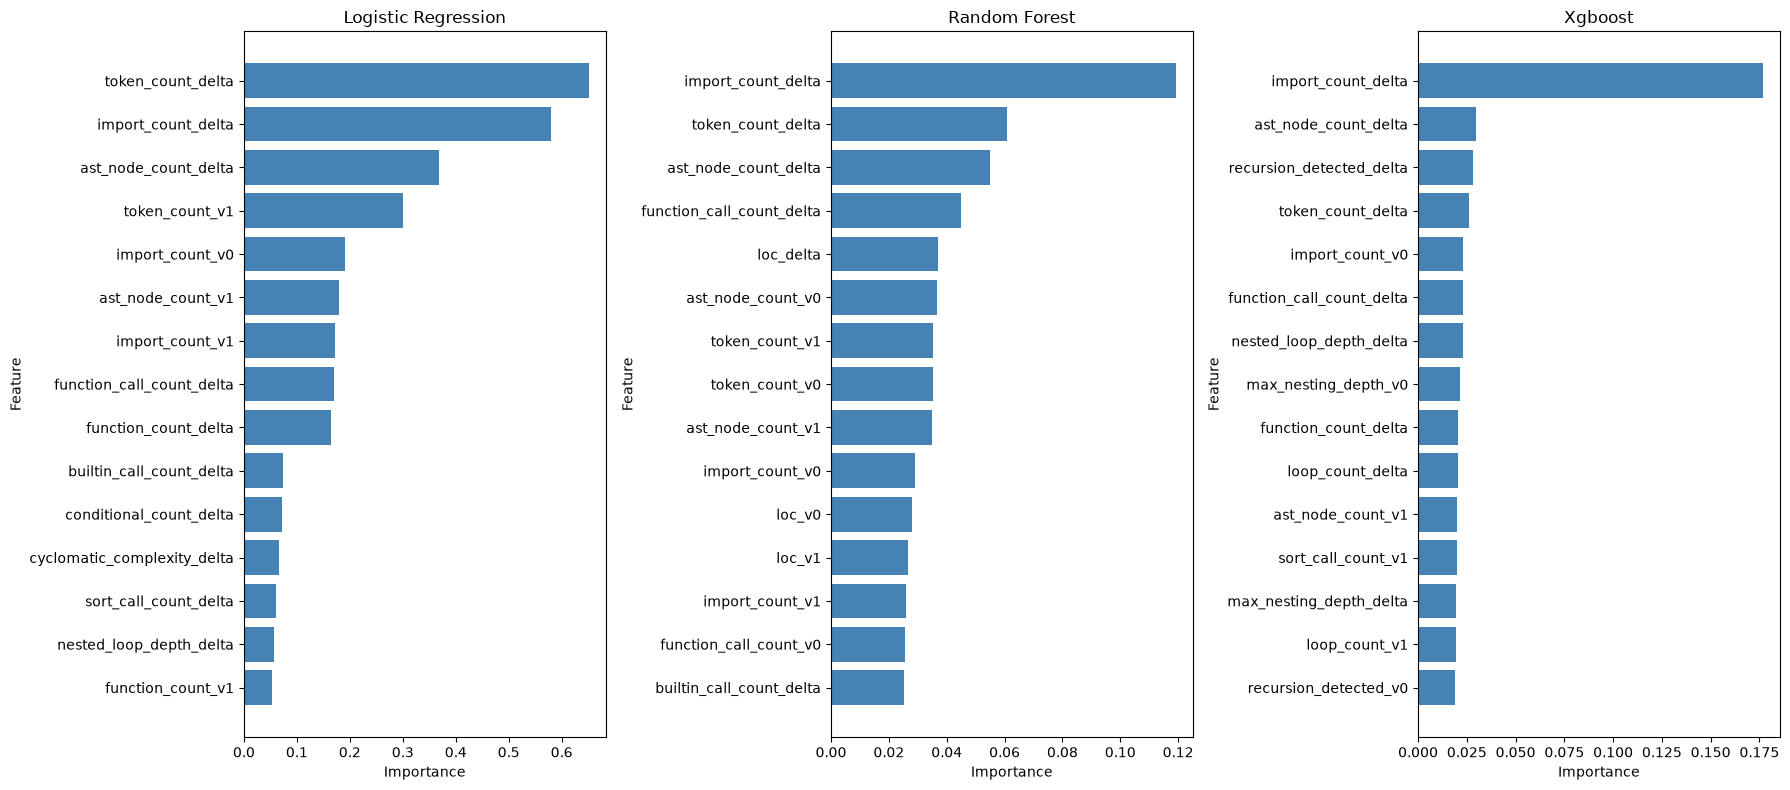

CodeBERT experiment scaffold: {
  "prepared_text_columns": [
    "code_v0_no_empty_lines",
    "code_v1_no_empty_lines"
  ],
  "target": "energy_winner",
  "group_column": "group_id",
  "implemented": false,
  "note": "The paired text and grouped target are saved; a CodeBERT fine-tuning run requires torch and transformers."
}


In [3]:
importance_tables = []
for model_name in ("logistic_regression", "random_forest", "xgboost"):
    estimator = fitted_models[model_name]
    if model_name == "logistic_regression":
        classifier = estimator[-1]
        importance = np.abs(classifier.coef_).mean(axis=0)
    else:
        importance = estimator.feature_importances_
    table = pd.DataFrame({"feature": X.columns, "importance": importance})
    table["model"] = model_name
    importance_tables.append(table)

feature_importance = pd.concat(importance_tables, ignore_index=True)
feature_importance.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)
for model_name, table in feature_importance.groupby("model"):
    top_features = table.nlargest(20, "importance")[["feature", "importance"]].reset_index(drop=True)
    print(f"\nTop 20 features: {model_name}")
    print(top_features.to_string(index=False, formatters={"importance": "{:.4f}".format}))
    display(top_features)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, model_name in zip(axes, ("logistic_regression", "random_forest", "xgboost")):
    top = feature_importance[feature_importance["model"] == model_name].nlargest(15, "importance")
    ax.barh(top["feature"], top["importance"], color="steelblue")
    ax.invert_yaxis()
    ax.set(title=model_name.replace("_", " ").title(), xlabel="Importance", ylabel="Feature")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance_top_features.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

CODEBERT_EXPERIMENT = manifest["codebert_experiment"]
print(
    "CodeBERT experiment scaffold:",
    json.dumps(CODEBERT_EXPERIMENT, indent=2),
)
